In [1]:
import pandas as pd
df = pd.read_csv("spotify_top_1000_tracks.csv")

Matplotlib is building the font cache; this may take a moment.


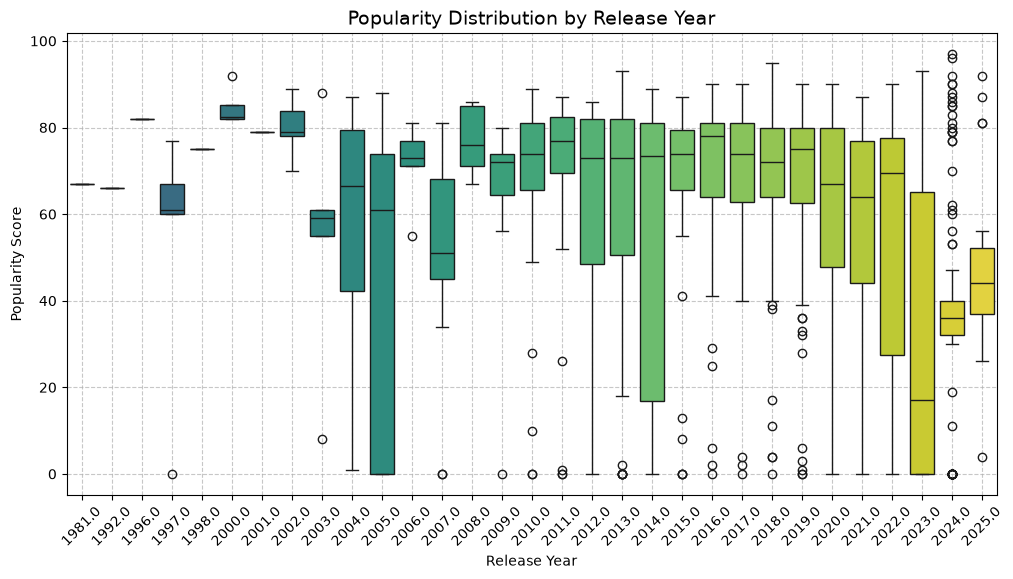

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# I-convert ang release_date para makuha ang year kung wala pa
if 'year' not in df.columns:
    df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
    df['year'] = df['release_date'].dt.year

plt.figure(figsize=(12, 6))
sns.boxplot(x='year', y='popularity', data=df, hue='year', palette='viridis', legend=False)
plt.title('Popularity Distribution by Release Year', fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Popularity Score')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

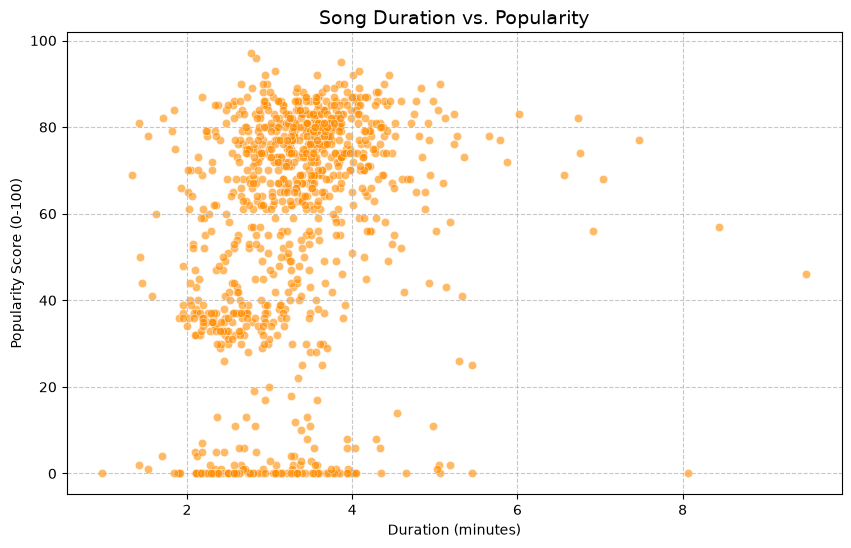

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='duration_min', y='popularity', data=df, alpha=0.6, color='darkorange') 
plt.title('Song Duration vs. Popularity', fontsize=14)
plt.xlabel('Duration (minutes)')
plt.ylabel('Popularity Score (0-100)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

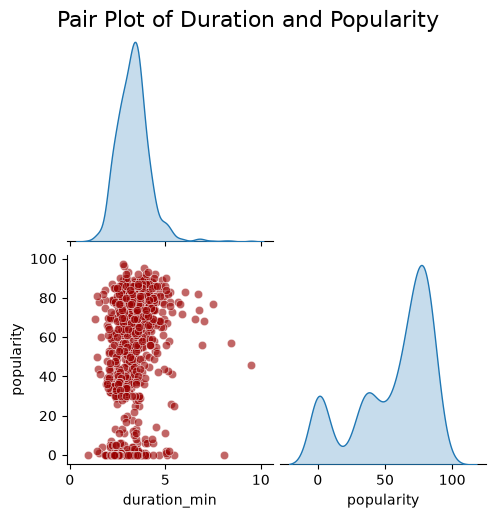

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

key_features = ['duration_min', 'popularity']
sns.pairplot(
    df[key_features], 
    diag_kind='kde', 
    corner=True, 
    plot_kws={'alpha': 0.6, 'color': '#990000'}
)
plt.suptitle('Pair Plot of Duration and Popularity', y=1.02, fontsize=16)
plt.show()

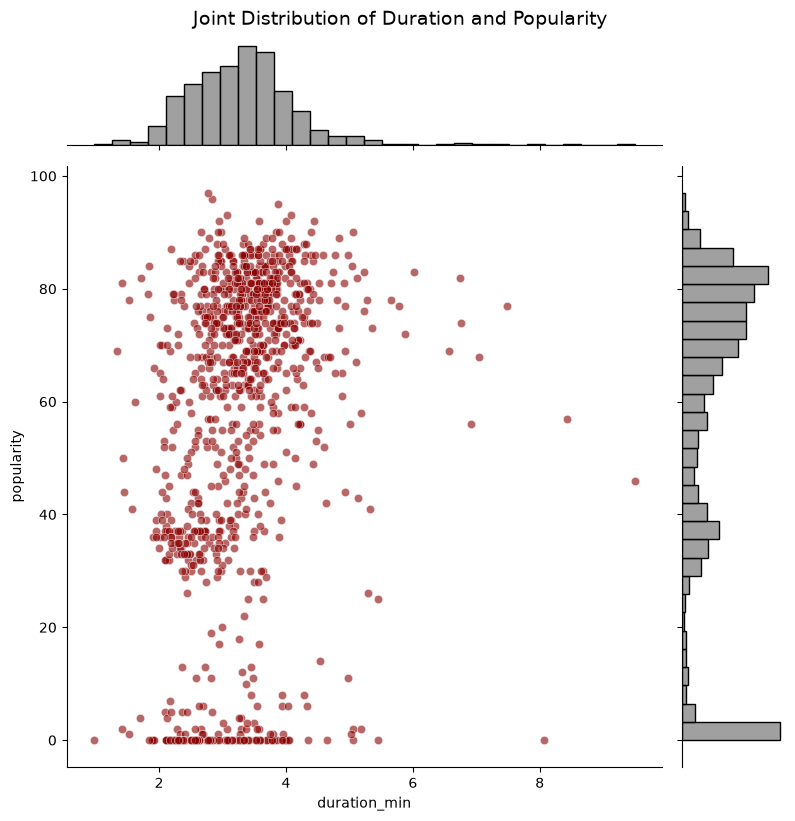

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.jointplot(
    x='duration_min', 
    y='popularity', 
    data=df, 
    kind='scatter', 
    height=8, 
    marginal_kws={'bins': 30, 'color': 'gray', 'edgecolor': 'black'},
    joint_kws={'alpha': 0.6, 'color': 'darkred'}
)
plt.suptitle('Joint Distribution of Duration and Popularity', y=1.02, fontsize=14)
plt.show()

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import webbrowser

yearly_popularity = df.groupby('year')['popularity'].mean().reset_index()
yearly_popularity = yearly_popularity.sort_values('year')

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(yearly_popularity['year'].min(), yearly_popularity['year'].max())
ax.set_ylim(0, yearly_popularity['popularity'].max() * 1.1)
line, = ax.plot([], [], color='royalblue', linewidth=2.5, label='Average Popularity')
ax.set_title("Evolution of Track Popularity Over Time", fontsize=14, color='navy')
ax.set_xlabel("Year of Release", fontsize=12)
ax.set_ylabel("Average Popularity", fontsize=12)
ax.legend(loc="upper left")
plt.tight_layout()

def animate(i):
    x = yearly_popularity['year'][:i]
    y = yearly_popularity['popularity'][:i]
    line.set_data(x, y)
    return line,

ani = FuncAnimation(fig, animate, frames=len(yearly_popularity), interval=100, repeat=False)

gif_path = os.path.abspath("yearly_popularity_trend.gif")
ani.save(gif_path, writer=PillowWriter(fps=10))
print(f"GIF saved successfully at: {gif_path}")

webbrowser.open(f"file://{gif_path}")
plt.close(fig)

GIF saved successfully at: d:\Downloads\BSECE-1C, 1st Sem\ComProg\Lab8_Data_Visualization_Soliva\yearly_popularity_trend.gif


,track_name,artist,duration_min
710,Lost Boy,Jaden,9.497883
610,I'm Getting Ready,Tasha Cobbs Leonard,8.436667
64,Mirrors,Justin Timberlake,8.069100
63,What Goes Around.../...Comes Around (Interlude),Justin Timberlake,7.476217
622,Achilles Come Down,Gang of Youths,7.035767
689,Never Let Go (Of Me),Baltra,6.909833
682,House Of Balloons / Glass Table Girls,The Weeknd,6.753550
549,Stan,Eminem,6.735100
671,Galvanize,The Chemical Brothers,6.563550
37,After Hours,The Weeknd,6.017100


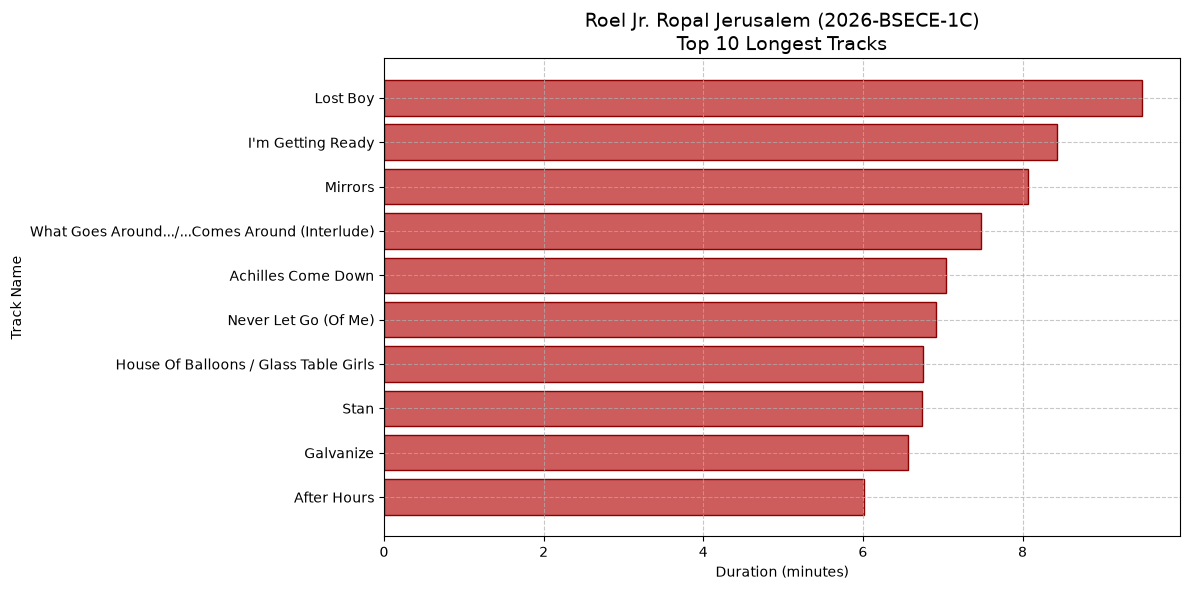

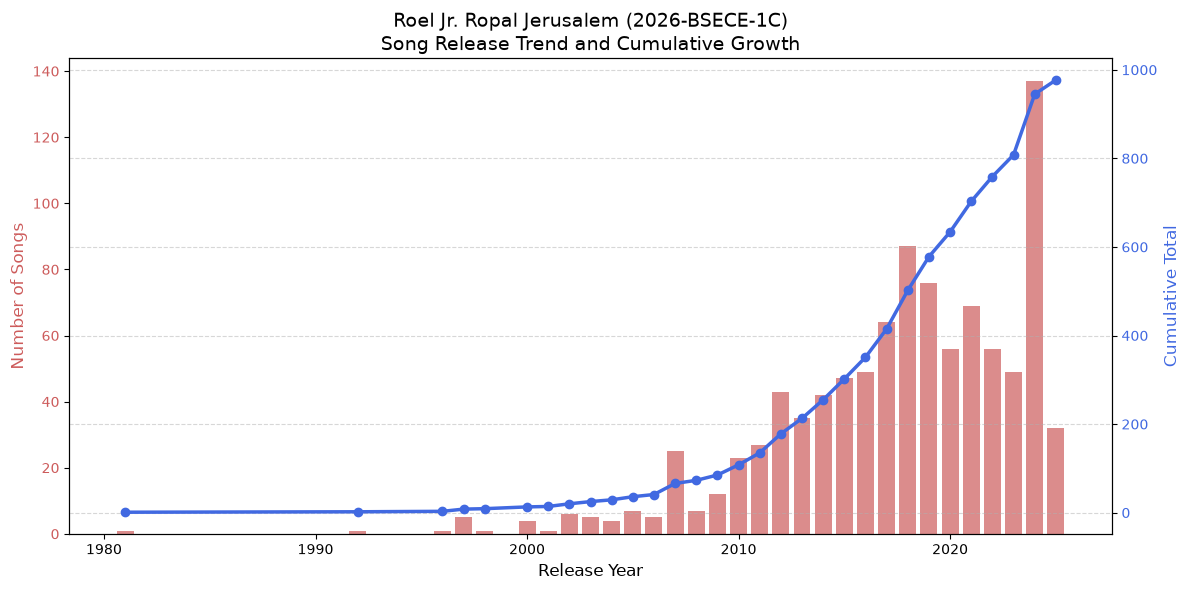

GIF saved successfully at: d:\Downloads\BSECE-1C, 1st Sem\ComProg\Lab8_Data_Visualization_Soliva\animated_hexbin_density.gif


In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation, PillowWriter
import webbrowser

df = pd.read_csv("spotify_top_1000_tracks.csv")

student_name = "Roel Jr. Ropal Jerusalem"
student_id = "2026-BSECE-1C"
color_bar = "indianred"
color_line = "royalblue"
cmap_color = "coolwarm"

longest_tracks = df.nlargest(10, 'duration_min')
display(longest_tracks[['track_name', 'artist', 'duration_min']])

plt.figure(figsize=(12, 6))
plt.barh(longest_tracks['track_name'], longest_tracks['duration_min'], color=color_bar, edgecolor='darkred')
plt.title(f"{student_name} ({student_id})\nTop 10 Longest Tracks", fontsize=14)
plt.xlabel('Duration (minutes)')
plt.ylabel('Track Name')
plt.gca().invert_yaxis()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year
yearly_counts = df.groupby('year').size().reset_index(name='count')
yearly_counts['cumulative'] = yearly_counts['count'].cumsum()
yearly_counts = yearly_counts.sort_values('year')

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(yearly_counts['year'], yearly_counts['count'], color=color_bar, alpha=0.7, label='Yearly Count')
ax1.set_xlabel('Release Year', fontsize=12)
ax1.set_ylabel('Number of Songs', color=color_bar, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_bar)

ax2 = ax1.twinx()
ax2.plot(yearly_counts['year'], yearly_counts['cumulative'], color=color_line, linewidth=2.5, marker='o', label='Cumulative Growth')
ax2.set_ylabel('Cumulative Total', color=color_line, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_line)

plt.title(f"{student_name} ({student_id})\nSong Release Trend and Cumulative Growth", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

df_anim = df.dropna(subset=['year', 'duration_min', 'popularity']).copy()
df_anim['year'] = df_anim['year'].astype(int)
years_sorted = sorted(df_anim['year'].unique())

fig_anim, ax_anim = plt.subplots(figsize=(10, 6))

def animate_hexbin(i):
    ax_anim.clear()
    current_year = years_sorted[i]
    subset = df_anim[df_anim['year'] <= current_year]
    hb = ax_anim.hexbin(subset['duration_min'], subset['popularity'], gridsize=20, cmap=cmap_color, mincnt=1, alpha=0.8)
    ax_anim.set_xlim(df_anim['duration_min'].min() - 0.5, df_anim['duration_min'].max() + 0.5)
    ax_anim.set_ylim(-5, 105)
    ax_anim.set_title(f"{student_name} ({student_id})\nAnimated Hexbin Density (Up to Year: {current_year})", fontsize=14)
    ax_anim.set_xlabel("Duration (minutes)")
    ax_anim.set_ylabel("Popularity Score")
    return hb,

anim = FuncAnimation(fig_anim, animate_hexbin, frames=len(years_sorted), interval=300, repeat=False)
gif_path = os.path.abspath("animated_hexbin_density.gif")
anim.save(gif_path, writer=PillowWriter(fps=5))
print(f"GIF saved successfully at: {gif_path}")
webbrowser.open(f"file://{gif_path}")
plt.close(fig_anim)

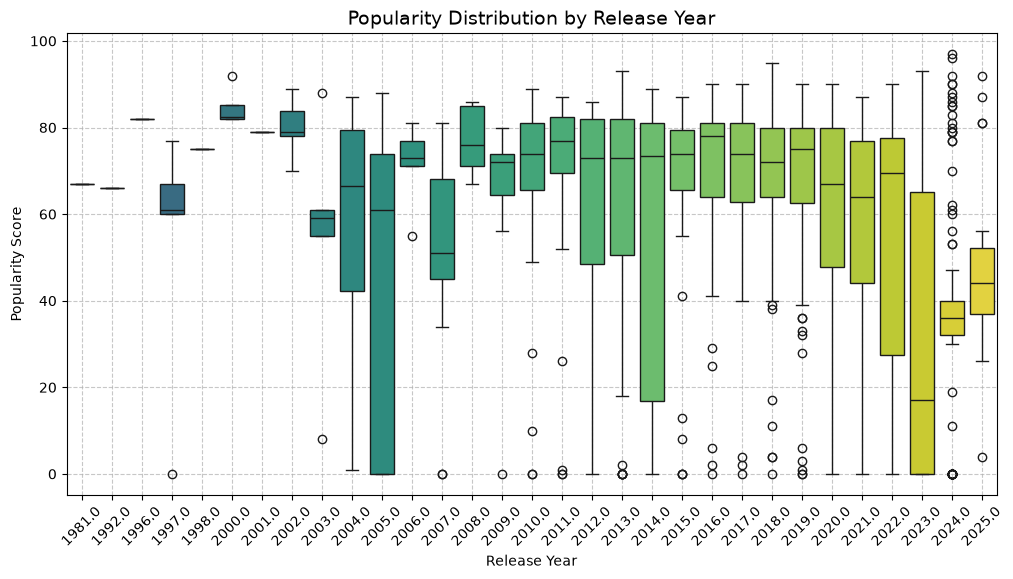

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# I-convert ang release_date para makuha ang year kung wala pa
if 'year' not in df.columns:
    df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
    df['year'] = df['release_date'].dt.year

plt.figure(figsize=(12, 6))
sns.boxplot(x='year', y='popularity', data=df, hue='year', palette='viridis', legend=False)
plt.title('Popularity Distribution by Release Year', fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Popularity Score')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


,track_name,artist,duration_min
710,Lost Boy,Jaden,9.497883
610,I'm Getting Ready,Tasha Cobbs Leonard,8.436667
64,Mirrors,Justin Timberlake,8.069100
63,What Goes Around.../...Comes Around (Interlude),Justin Timberlake,7.476217
622,Achilles Come Down,Gang of Youths,7.035767
689,Never Let Go (Of Me),Baltra,6.909833
682,House Of Balloons / Glass Table Girls,The Weeknd,6.753550
549,Stan,Eminem,6.735100
671,Galvanize,The Chemical Brothers,6.563550
37,After Hours,The Weeknd,6.017100


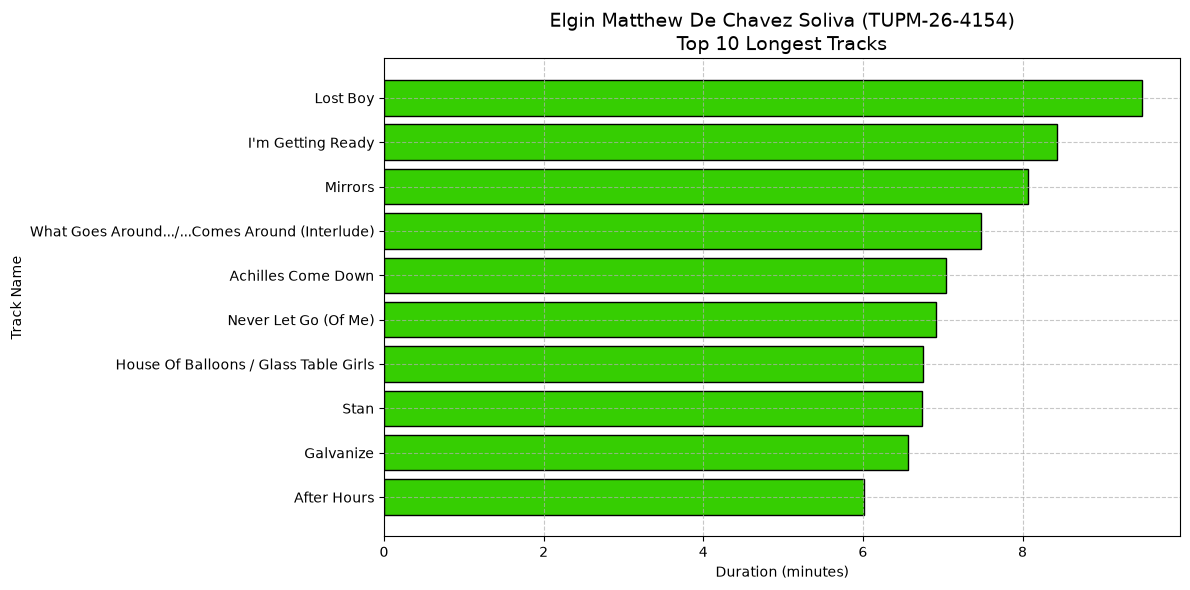

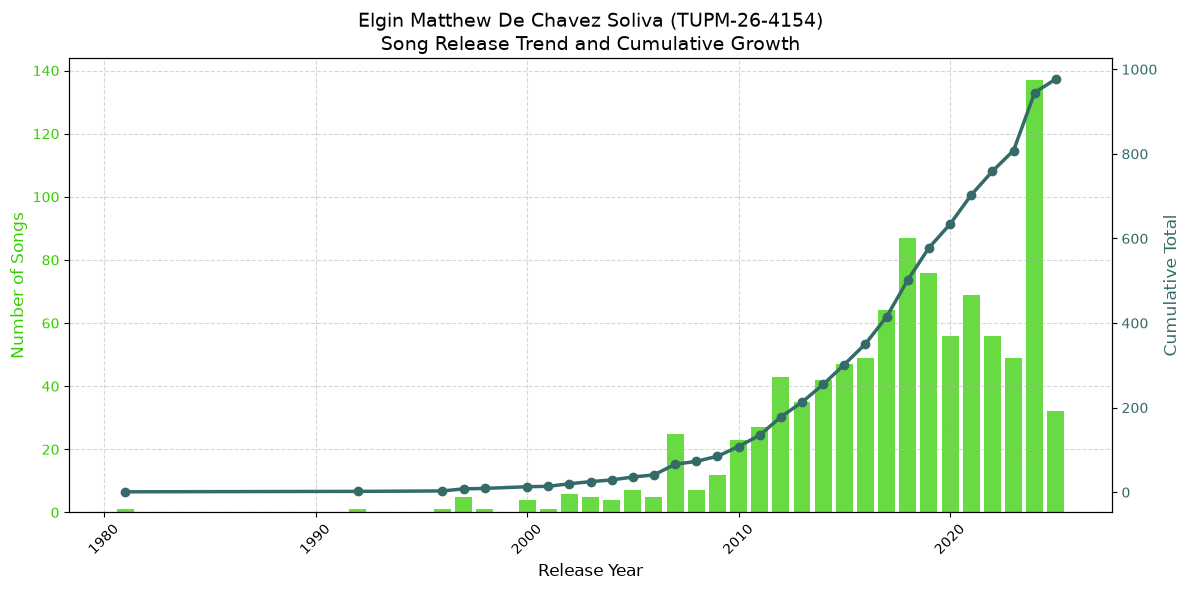

GIF saved successfully at: d:\Downloads\BSECE-1C, 1st Sem\ComProg\Lab8_Data_Visualization_Soliva\animated_hexbin_density.gif


In [13]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation, PillowWriter
import webbrowser

df = pd.read_csv("spotify_top_1000_tracks.csv", encoding="utf-8")

student_name = "Elgin Matthew De Chavez Soliva"
student_id = "TUPM-26-4154"
id_num = int(student_id[-3:])  # 154
color_bar = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"   # #32ce02
color_line = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"  # #346a68
cmap_color = "coolwarm"

# Exercise 1: Top 10 Longest Tracks
longest_tracks = df.nlargest(10, "duration_min")
display(longest_tracks[["track_name", "artist", "duration_min"]])

plt.figure(figsize=(12, 6))
plt.barh(
    longest_tracks["track_name"],
    longest_tracks["duration_min"],
    color=color_bar,
    edgecolor="black",
)
plt.title(f"{student_name} ({student_id})\nTop 10 Longest Tracks", fontsize=14)
plt.xlabel("Duration (minutes)")
plt.ylabel("Track Name")
plt.gca().invert_yaxis()
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# Exercise 2: Song Release Trend and Cumulative Growth
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year
yearly_counts = df.dropna(subset=["year"]).groupby("year").size().reset_index(name="count")
yearly_counts["year"] = yearly_counts["year"].astype(int)
yearly_counts = yearly_counts.sort_values("year")
yearly_counts["cumulative"] = yearly_counts["count"].cumsum()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(
    yearly_counts["year"],
    yearly_counts["count"],
    color=color_bar,
    alpha=0.75,
    label="Yearly Count",
)
ax1.set_xlabel("Release Year", fontsize=12)
ax1.set_ylabel("Number of Songs", color=color_bar, fontsize=12)
ax1.tick_params(axis="y", labelcolor=color_bar)
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(
    yearly_counts["year"],
    yearly_counts["cumulative"],
    color=color_line,
    linewidth=2.5,
    marker="o",
    label="Cumulative Growth",
)
ax2.set_ylabel("Cumulative Total", color=color_line, fontsize=12)
ax2.tick_params(axis="y", labelcolor=color_line)

plt.title(f"{student_name} ({student_id})\nSong Release Trend and Cumulative Growth", fontsize=14)
ax1.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

# Exercise 3: Animated Hexbin Density Map
df_anim = df.dropna(subset=["year", "duration_min", "popularity"]).copy()
df_anim["year"] = df_anim["year"].astype(int)
years_sorted = sorted(df_anim["year"].unique())

fig_anim, ax_anim = plt.subplots(figsize=(10, 6))

def animate_hexbin(i):
    ax_anim.clear()
    current_year = years_sorted[i]
    subset = df_anim[df_anim["year"] <= current_year]
    hb = ax_anim.hexbin(
        subset["duration_min"],
        subset["popularity"],
        gridsize=20,
        cmap=cmap_color,
        mincnt=1,
        alpha=0.85,
    )
    ax_anim.set_xlim(df_anim["duration_min"].min() - 0.5, df_anim["duration_min"].max() + 0.5)
    ax_anim.set_ylim(-5, 105)
    ax_anim.set_title(
        f"{student_name} ({student_id})\nAnimated Hexbin Density (Up to Year: {current_year})",
        fontsize=14,
    )
    ax_anim.set_xlabel("Duration (minutes)")
    ax_anim.set_ylabel("Popularity Score")
    return (hb,)

anim = FuncAnimation(fig_anim, animate_hexbin, frames=len(years_sorted), interval=300, repeat=False)
gif_path = os.path.abspath("animated_hexbin_density.gif")
anim.save(gif_path, writer=PillowWriter(fps=5))
print(f"GIF saved successfully at: {gif_path}")
webbrowser.open(f"file://{gif_path}")
plt.close(fig_anim)